# ACN-Data joint stochastic modeling

Person B extends the preprocessing and dependency diagnostics with competing stochastic session generators.
The present target is **plug-in time, dwell time and delivered energy**. Departure is derived, rather than independently sampled.

The static Git snapshot and the API session exports are different data products. This notebook reads the entire selected session table; it does not load all static time-series files.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)

working_directory = Path.cwd()
project_root = working_directory if (working_directory / "codespace/person_b_models.py").exists() else working_directory.parent
assert (project_root / "codespace/person_b_models.py").exists(), "Start from the project root or codespace."
sys.path.insert(0, str(project_root / "codespace"))
from person_b_models import run, LABELS

results_path = project_root / "codespace/person_b_results"
print("Python:", sys.executable)

Python: /opt/anaconda3/bin/python


## Reproduce the experiment

Set `RUN_EXPERIMENT = True` to re-read data and regenerate output files. With `INPUT_PATH = None`, the loader prefers `codespace/clean_sessions.parquet`, then root `clean_sessions.parquet`, otherwise the PARTIAL CSV.
Use a different output directory when switching data sources. The raw data and Person A notebook are not modified.

After changing data or site, update the narrative findings as well as the numeric outputs. The current narrative describes the recorded Caltech and Office snapshots.

In [2]:
RUN_EXPERIMENT = False
INPUT_PATH = None
SITE_ID = "0002"
REPEATS = 10

if RUN_EXPERIMENT:
    rerun_summary, rerun_metadata = run(INPUT_PATH, results_path, SITE_ID, REPEATS)
    display(rerun_summary[["selection_score_mean", "occupancy_mae_mean"]])
else:
    print("Saved results displayed; training was not rerun.")

Saved results displayed; training was not rerun.


## Verify data provenance

The directory inventory contains 85,877 static `.csv.gz` files, matching the upstream README counts. This checks file counts, not archive integrity. Only a few files were opened for schema inspection.

The model input is `raw_acn/all_sessions_PARTIAL.csv`, a separate API-session export. Its coverage status is partial for Caltech/JPL and complete for Office 1. A complete Git checkout can therefore contain a partial API export.

Static time-series endpoints describe measurements; their final timestamp must not automatically be treated as the unplug time. User-request histories are also absent from the sampled static CSV schema.

In [3]:
coverage_audit = json.loads((results_path / "data_coverage_audit.json").read_text())
static_inventory = pd.Series(coverage_audit["static_time_series_counts"], name="local_files")
display(static_inventory.to_frame())
print("Static total:", coverage_audit["static_total_files"])
api_coverage = pd.DataFrame.from_dict(coverage_audit["api_snapshot_status"], orient="index")
display(api_coverage[["downloaded_records", "api_total", "complete"]])

,local_files
caltech/California_Garage_01,31860
caltech/California_Garage_02,15589
caltech/LIGO_01,229
caltech/N_Wilson_Garage_01,6299
caltech/S_Wilson_Garage_01,2703
jpl/Arroyo_Garage_01,27723
office_01/Parking_Lot_01,1474


Static total: 85877


,downloaded_records,api_total,complete
caltech,23200,31424,False
jpl,16700,33638,False
office001,1683,1683,True


## Load the experiment record

The first model uses Caltech (`0002`), consistent with the preprocessing notebook. This adapter uses UTC timestamps without minute rounding, then derives local clock hours. It preserves positive-session tails and performs no request imputation. Missing IDs are kept; repeated nonmissing IDs are deduplicated.

Saved results are loaded by default. This avoids re-reading raw data just to inspect the report.

In [4]:
run_metadata = json.loads((results_path / "run_metadata.json").read_text())
display(pd.Series(run_metadata["audit"], name="value").to_frame())

,value
input,/Users/alexshang/Desktop/EV-Charing-Simulator/raw_acn/all_sessions_PARTIAL.csv
siteID,0002
site_rows,23200
duplicate_id_rows,0
missing_or_nonfinite_rows,0
nonpositive_dwell_rows,0
nonpositive_energy_rows,0
retained_rows,23200
note,Exclusion reasons may overlap. Positive-session target; no tail trimming.


## Chronological validation

The final 20% of observed dates are reserved for exploratory evaluation. Earlier data provide two expanding-window validation folds: first 40% → next 20%, and first 60% → next 20%. Model configurations and the preferred method use only those validation folds; the model is then refitted on the first 80%.

This evaluation period was already inspected in the initial development round. It must not be described as a pristine confirmatory test. Future claims need newly held-out data.

All generators receive the same evaluation-date session counts. This isolates session-variable quality and does not evaluate an arrival-count model.

In [5]:
split_summary = pd.DataFrame(run_metadata["splits"]).T
split_summary = split_summary[["rows", "observed_dates", "first_date", "last_date"]]
display(split_summary)
validation_scores = pd.read_csv(results_path / "validation_scores.csv")
validation_best = validation_scores.loc[validation_scores.groupby("method")["validation_score"].idxmin()]
display(validation_best.sort_values("validation_score").set_index("method").round(4))

,rows,observed_dates,first_date,last_date
train,17046,306,2018-04-25,2019-02-24
validation,3301,102,2019-02-25,2019-06-06
test,2853,103,2019-06-07,2019-09-17


,config,validation_score,fold_1_score,fold_2_score
method,,,,
calendar_bootstrap,"{""half_life"": 30}",0.0439,0.0537,0.0340
circular_neighbors,"{""neighbors"": 50}",0.0545,0.0518,0.0572
joint_kde,"{""bandwidth"": 0.5}",0.0573,0.0525,0.0622
conditional_pairs,"{""bins"": 6}",0.0574,0.0524,0.0625
session_bootstrap,{},0.0574,0.0559,0.0590
gaussian_copula,{},0.0676,0.0636,0.0716
independent_empirical,{},0.1163,0.1164,0.1161
independent,{},0.1249,0.1249,0.1249


## Candidate generators

All methods condition on weekday/weekend; training groups smaller than 30 records pool to the training population.

| Method | Joint-generation mechanism | Purpose |
|---|---|---|
| Independent parametric | Empirical arrival, separate positive parametric dwell/energy | Conventional baseline |
| Independent empirical | Separate draws from the same empirical margins | Isolate dependency loss |
| Conditional pairs | Arrival quantile bins; paired dwell/energy | Simple conditional baseline |
| Circular neighbors | Nearest arrival hours on a 24-hour circle; paired dwell/energy | Avoid hard bin boundaries |
| Joint KDE | sin/cos arrival and log-positive variables | Smooth joint generation |
| Gaussian copula | Empirical margins and Gaussian rank dependence | Separate margins and dependence |
| Session bootstrap | Draw complete session tuples | Preserve observed session-level structure |
| Calendar bootstrap | Complete tuples weighted by target month and training age | Adapt to changing behavior |

KDE projects out deterministic dimensions rather than injecting artificial jitter. Calendar weighting is a heuristic; it does not prove that the observed change is behavioral rather than coverage-related.

## Exploratory model comparison

The heuristic score averages three KS distances and three absolute Spearman errors divided by two. Conditional KS checks dwell and energy within fixed four-hour arrival bins; sparse bins are omitted.

The added empirical independent baseline matters: the initial independent model mixed loss of dependence with parametric marginal errors. Comparisons can now distinguish those effects.

,score,seed_SD,conditional_KS,occupancy_MAE,invalid_share
method,,,,,
calendar_bootstrap,0.0391,0.0025,0.1163,2.0835,0.0
conditional_pairs,0.0607,0.0043,0.1628,2.6040,0.0
circular_neighbors,0.0611,0.0022,0.1494,2.4522,0.0
session_bootstrap,0.0623,0.0037,0.1433,2.4940,0.0
joint_kde,0.0647,0.0034,0.1493,2.5678,0.0
gaussian_copula,0.0710,0.0039,0.2284,3.2416,0.0
independent_empirical,0.1165,0.0044,0.2227,3.7821,0.0
independent,0.1243,0.0034,0.2244,4.1154,0.0


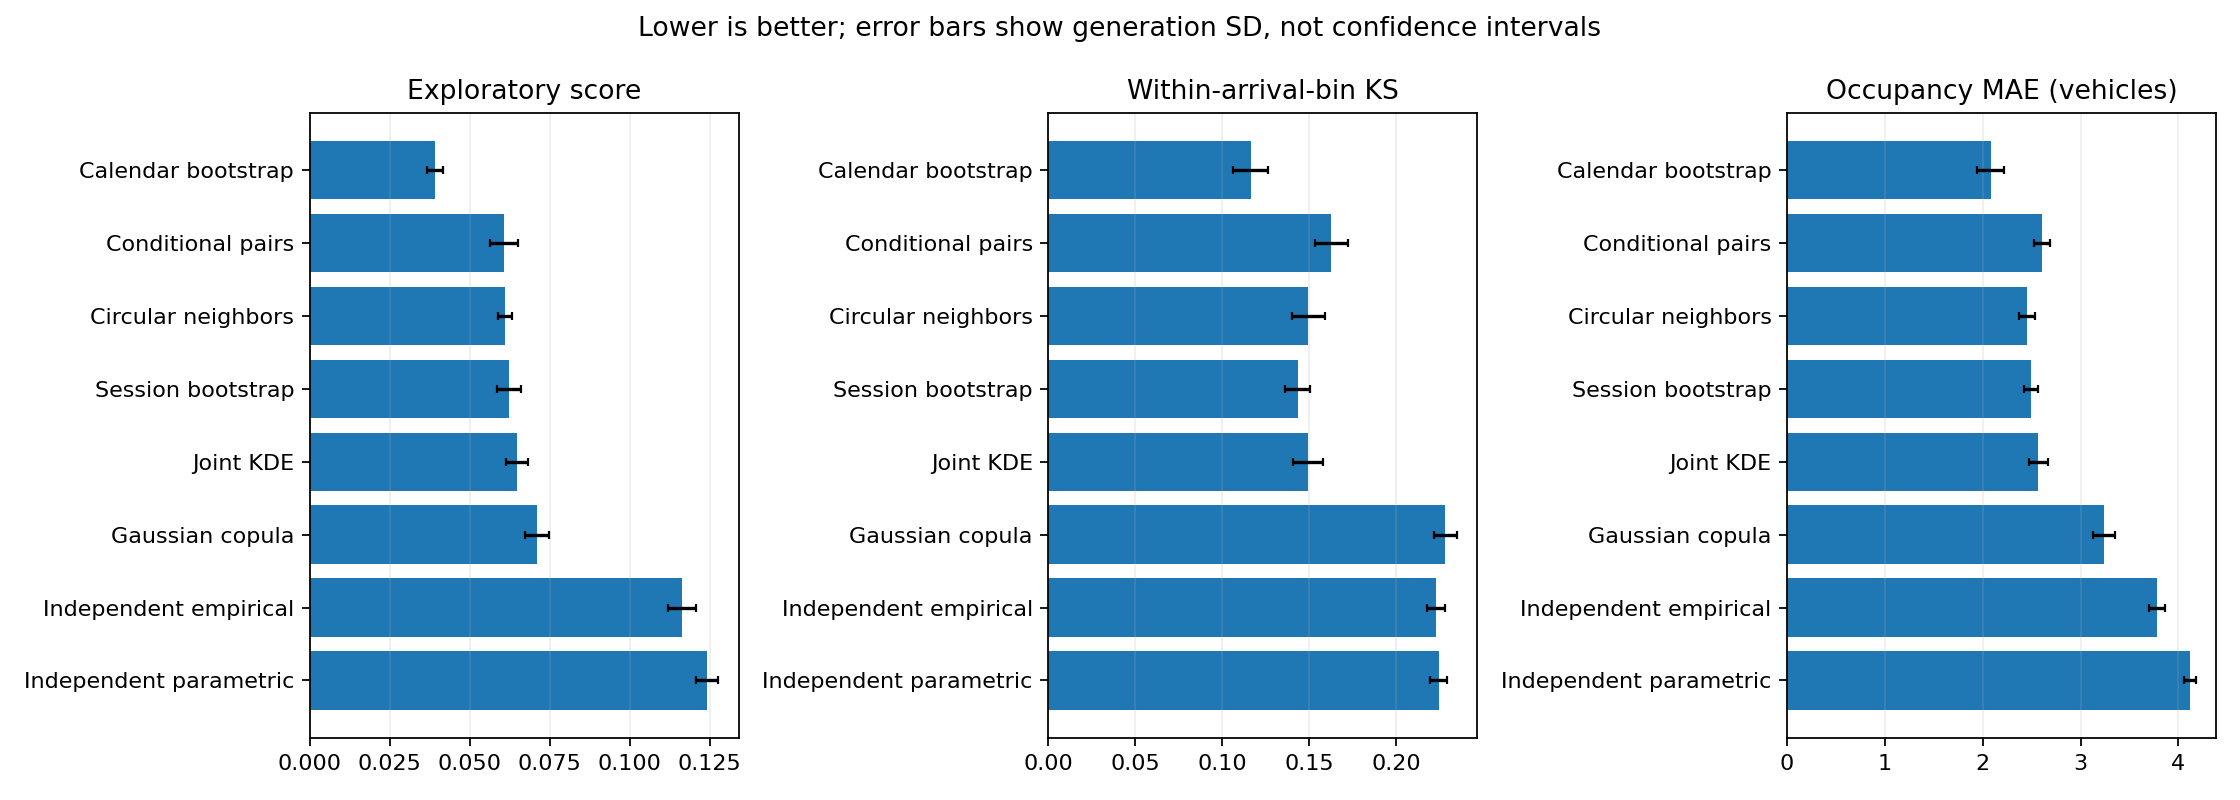

In [6]:
model_comparison = pd.read_csv(results_path / "model_comparison.csv", index_col="method")
score_columns = ["selection_score_mean", "selection_score_std", "conditional_ks_mean", "occupancy_mae_mean", "invalid_fraction_mean"]
score_summary = model_comparison[score_columns].rename(columns={
    "selection_score_mean": "score", "selection_score_std": "seed_SD",
    "conditional_ks_mean": "conditional_KS", "occupancy_mae_mean": "occupancy_MAE",
    "invalid_fraction_mean": "invalid_share",
})
display(score_summary.round(4))
display(Image(filename=str(results_path / "comparison_dashboard.png")))

### Marginal fidelity

The ECDF panels compare arrival, dwell and delivered energy. Plot limits use the real 99th percentile for readability; all retained tails enter numeric evaluation. Error units for Wasserstein distance are hours or kWh.

,ks_arrival_mean,ks_dwell_mean,ks_energy_mean
method,,,
calendar_bootstrap,0.0888,0.0552,0.0531
conditional_pairs,0.1175,0.0544,0.1258
circular_neighbors,0.1175,0.0533,0.1320
session_bootstrap,0.1197,0.0542,0.1285
joint_kde,0.1243,0.0713,0.1243
gaussian_copula,0.1250,0.0535,0.1268
independent_empirical,0.1192,0.0579,0.1247
independent,0.1228,0.1031,0.1204


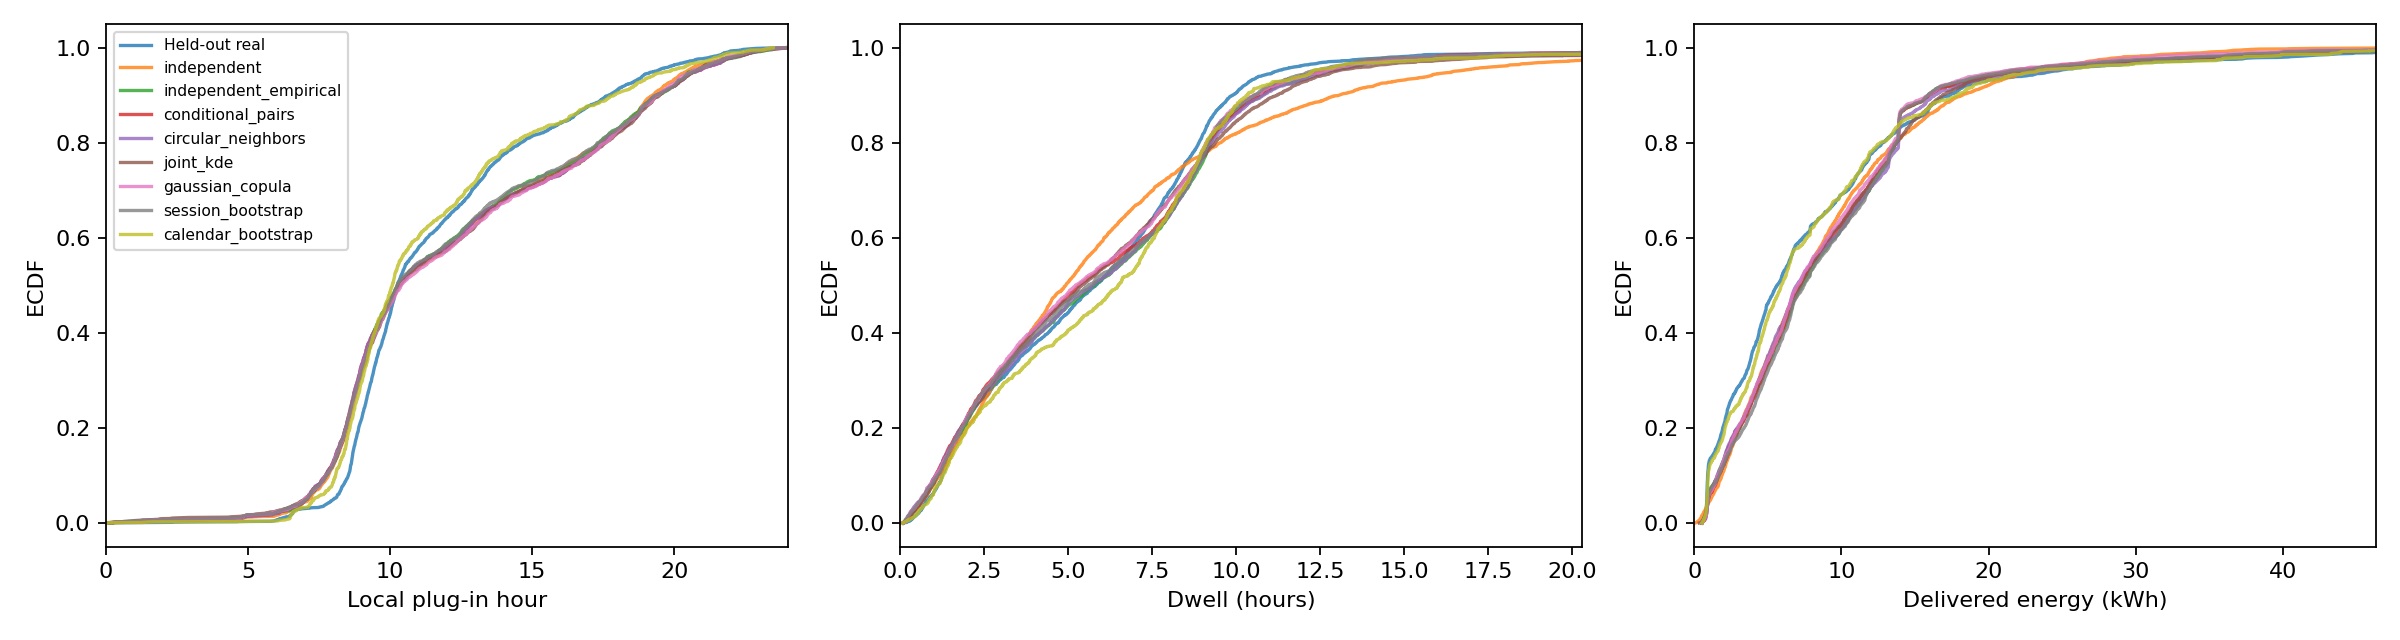

In [7]:
marginal_columns = ["ks_arrival_mean", "ks_dwell_mean", "ks_energy_mean"]
display(model_comparison[marginal_columns].round(4))
display(Image(filename=str(results_path / "marginals.png")))

### Arrival and dwell

A single correlation does not characterize every joint pattern. The larger panels make conditional shape visible; compare short dwell among later arrivals and the morning concentration.

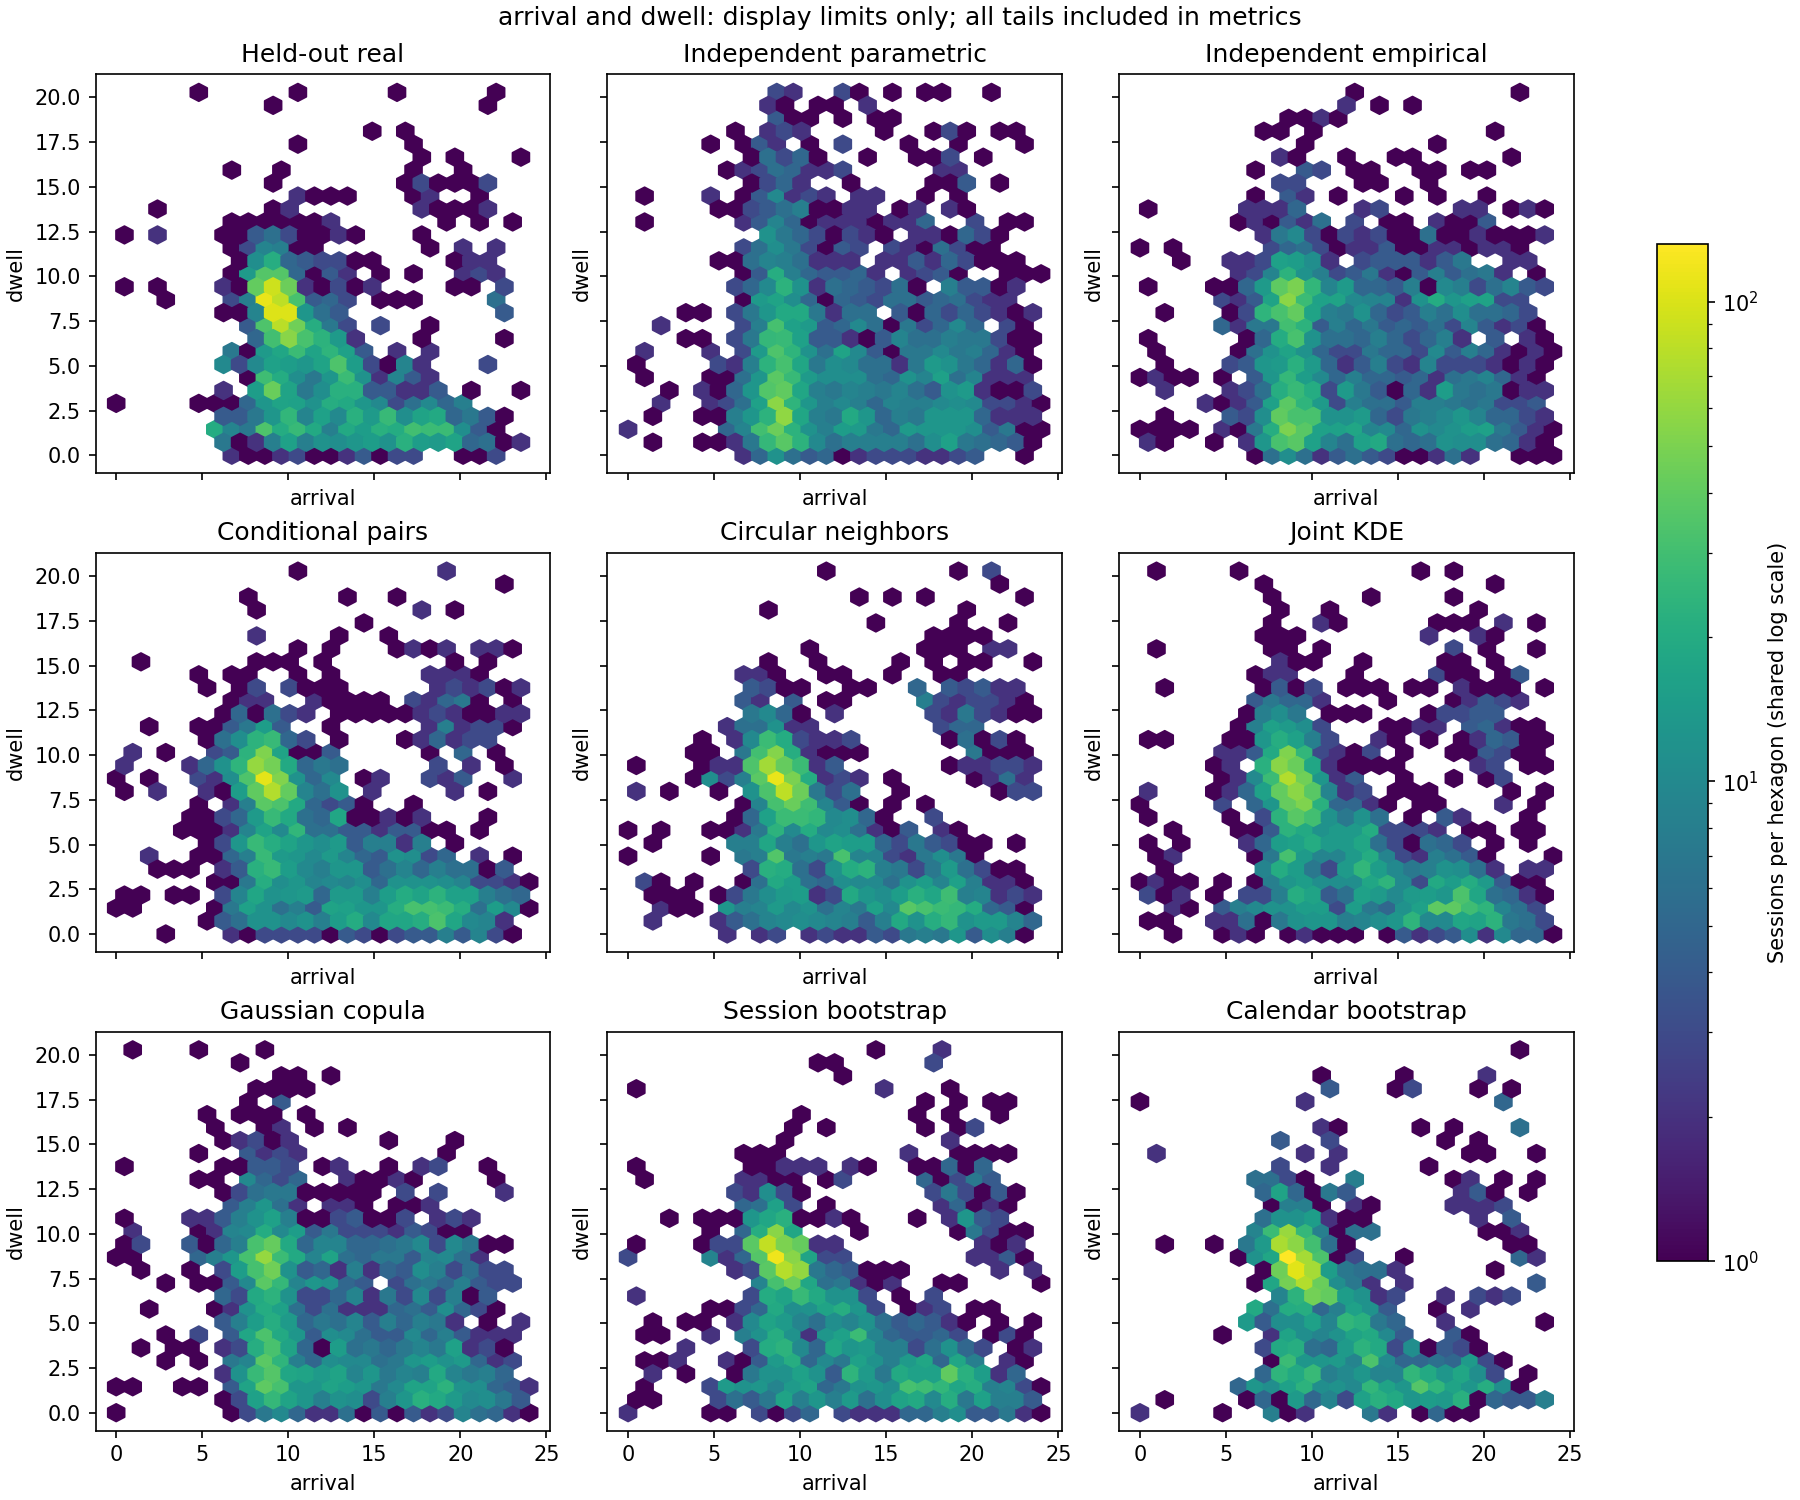

In [8]:
display(Image(filename=str(results_path / "joint_distributions.png")))

### Dwell and delivered energy

Keeping an observed dwell/energy pair preserves its relationship. Independent draws can produce a plausible dwell histogram and energy histogram while combining them in implausible ways.

,corr_error_arrival_dwell_mean,corr_error_dwell_energy_mean,corr_error_arrival_energy_mean
method,,,
calendar_bootstrap,0.0242,0.0160,0.0347
conditional_pairs,0.0160,0.0751,0.0422
circular_neighbors,0.0124,0.0820,0.0334
session_bootstrap,0.0228,0.0799,0.0401
joint_kde,0.0249,0.0710,0.0411
gaussian_copula,0.1193,0.0866,0.0359
independent_empirical,0.3794,0.2995,0.1153
independent,0.3787,0.3107,0.1095


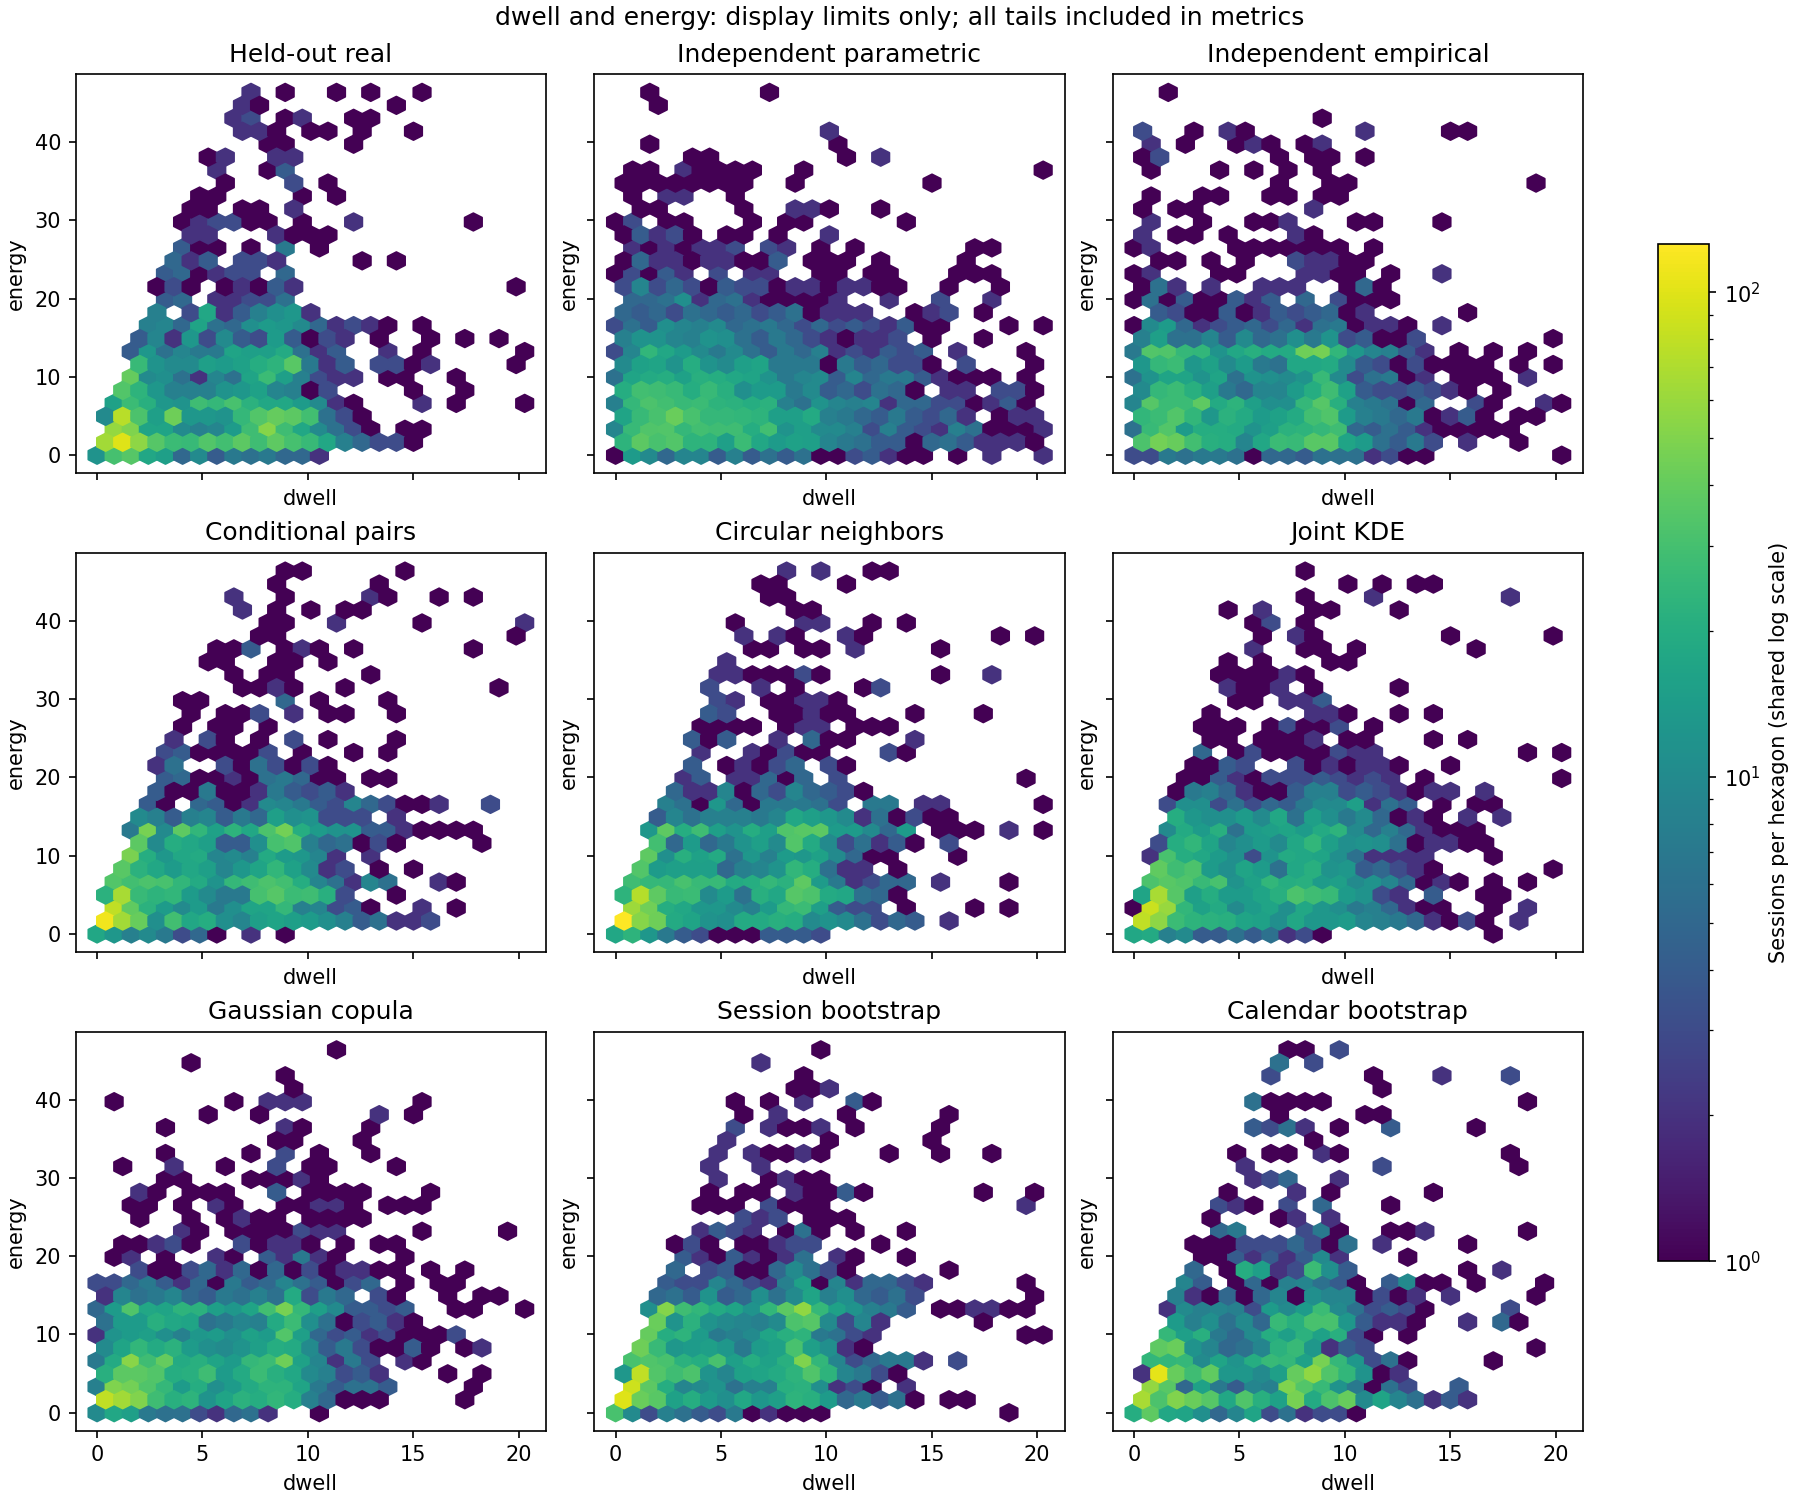

In [9]:
dependency_columns = ["corr_error_arrival_dwell_mean", "corr_error_dwell_energy_mean", "corr_error_arrival_energy_mean"]
display(model_comparison[dependency_columns].round(4))
display(Image(filename=str(results_path / "joint_energy.png")))

### Plug-in occupancy

Occupancy counts vehicles connected at each 15-minute instant, including sessions spanning midnight. It is neither queue length nor charging power. The metric uses observed dates and skips the first seven days when possible because pre-period sessions are not available. Very long carry-in remains a limitation.

The plotted trajectories use one seed; seed SD in the table reflects generation randomness only, not confidence intervals.

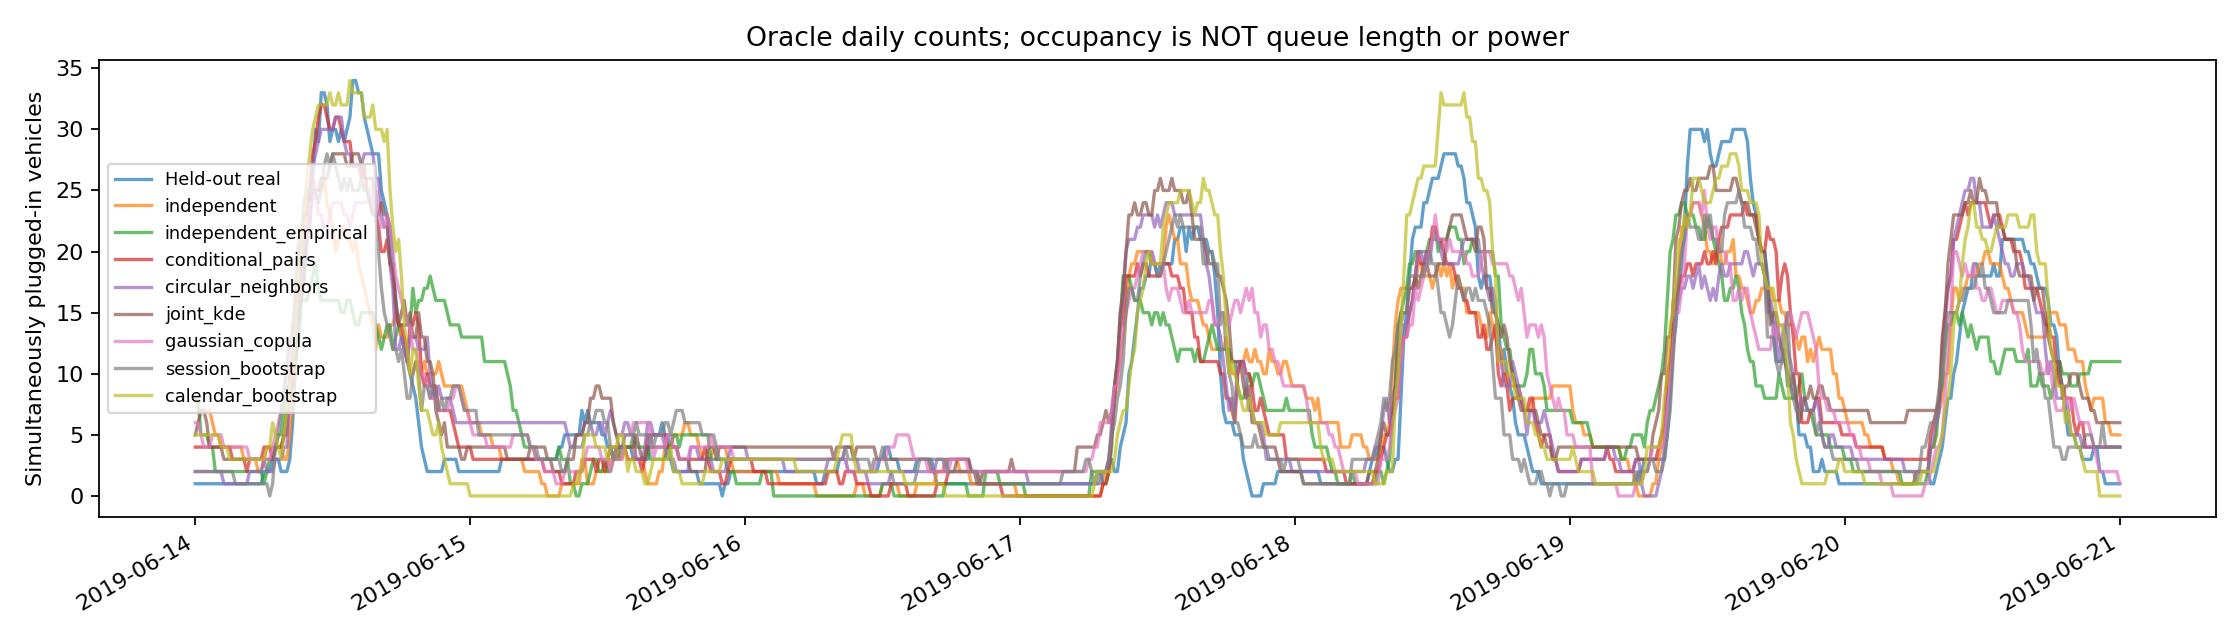

In [10]:
display(Image(filename=str(results_path / "occupancy.png")))

## Findings from the current snapshot

- Calendar bootstrap is preferred by the average earlier validation score, with a selected **30-day half-life**. Its exploratory score is approximately **0.039**, compared with **0.062** for unweighted session bootstrap.
- The gain is consistent with adapting to changes in observed arrival and energy patterns; coverage differences remain an alternative explanation.
- Calendar bootstrap does not win every validation fold. The result supports a candidate for further testing, not a universal best model.
- The empirical independent model remains worse than tuple-based methods, supporting the need to preserve joint dependence beyond matching margins.
- Conditional neighbors provide a simple alternative without arbitrary arrival-bin boundaries. KDE and copula remain useful comparison models; higher complexity is not automatically better.
- The earlier evaluation period has been reused during development. A final study should freeze the method and assess new data.

## Complete API-export sensitivity check: Office 1

A supplementary run uses the complete local Office 1 API export (1,683 sessions). Calendar weighting is also preferred by its earlier validation folds, selecting a **90-day** rather than 30-day half-life. This supports testing adaptive weights while keeping site-specific parameters.

Office 1 has only seven weekend sessions in the full snapshot, so the weekend fit is pooled and cannot establish a separate weekend model. It spans a different period, including pandemic-era changes; the comparison is not a controlled causal experiment. Occupancy errors across sites have different scales and should not be directly ranked.

In [11]:
office_results_path = project_root / "codespace/person_b_office_results"
if office_results_path.exists():
    office_metadata = json.loads((office_results_path / "run_metadata.json").read_text())
    print("Office retained sessions:", office_metadata["audit"]["retained_rows"])
    print("Validation-preferred method:", office_metadata["recommended_by_validation"])
    office_comparison = pd.read_csv(office_results_path / "model_comparison.csv", index_col="method")
    display(office_comparison[["selection_score_mean", "selection_score_std", "occupancy_mae_mean"]].round(4))
else:
    print("Supplementary Office experiment has not been run.")

Office retained sessions: 1683
Validation-preferred method: calendar_bootstrap


,selection_score_mean,selection_score_std,occupancy_mae_mean
method,,,
calendar_bootstrap,0.1001,0.0159,0.3639
conditional_pairs,0.1114,0.0080,0.3756
circular_neighbors,0.1149,0.0130,0.3718
session_bootstrap,0.1177,0.0176,0.3589
gaussian_copula,0.1220,0.0156,0.3787
joint_kde,0.1321,0.0119,0.3683
independent_empirical,0.1369,0.0150,0.4047
independent,0.1565,0.0110,0.4316


## Modeling decisions and next steps

#### 1. Retain an empirical joint baseline

Use complete session resampling as the transparent reference. Compare calendar weighting and conditional neighbors against it, using both validation periods, conditional fit and occupancy.

#### 2. Establish the arrival-count target

Ask Person A for verified observation windows. Then compare whole-day clustered bootstrap with an overdispersed count model plus conditional arrival timing. Missing downloaded dates must not be inserted as zero arrivals without evidence.

#### 3. Add requested energy and post-charge dwell coherently

Delivered energy is not requested energy. Use user-input versions available at the decision time; do not replace missing requests with delivered kWh. Model post-charge dwell jointly with charging completion and parking so generated times remain ordered.

#### 4. Test additional structure where justified

Whole-day bootstrap can preserve within-day co-movement. User clusters or random effects address repeated drivers. Transformed Gaussian mixtures or mixture-of-experts can represent distinct driver profiles. These extensions need coverage/schema agreement and appropriate cluster-held-out evaluation.

Detailed selection notes are in `person_b_results/model_selection_report.md`. Data definitions: [ACN-Data](https://ev.caltech.edu/dataset). KDE implementation notes: [SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gaussian_kde.html).

## Inspect a generated sample

The file contains the **validation-preferred** model's seed=200 sessions. It is synthetic data, not Person A's cleaned observations. Departure is calculated from connection + dwell.

In [12]:
synthetic_sessions = pd.read_parquet(results_path / "synthetic_sessions_example.parquet")
print("Validation-preferred method:", run_metadata["recommended_by_validation"])
display(synthetic_sessions.head())

Validation-preferred method: calendar_bootstrap


,arrival,dwell,energy,date,dayType,connection,departure
0,14.603056,1.499167,3.978,2019-06-07,Weekday,2019-06-07 21:36:11.000000001+00:00,2019-06-07 23:06:08.000000002+00:00
1,9.170833,7.199722,3.774,2019-06-07,Weekday,2019-06-07 16:10:15.999999999+00:00,2019-06-07 23:22:14.999999998+00:00
2,5.795556,5.251944,31.215,2019-06-07,Weekday,2019-06-07 12:47:44.000000001+00:00,2019-06-07 18:02:50.999999999+00:00
3,7.125278,10.025556,7.105,2019-06-07,Weekday,2019-06-07 14:07:31+00:00,2019-06-08 00:09:03.000000001+00:00
4,16.275000,3.593611,4.323,2019-06-07,Weekday,2019-06-07 23:16:30+00:00,2019-06-08 02:52:06.999999999+00:00
